In [ ]:
from google.colab import files
uploaded=files.upload()

Saving GermanCredit.xlsx to GermanCredit.xlsx


In [ ]:
import pandas as pd

df=pd.read_excel("GermanCredit.xlsx")
df.head()

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,...,real estate,67,none,own,2,skilled employee/official,1,yes,yes,1
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,...,real estate,22,none,own,1,skilled employee/official,1,no,yes,0
2,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,...,real estate,49,none,own,1,unskilled - resident,2,no,yes,1
3,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,...,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes,1
4,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,...,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes,0


In [ ]:
## dataset information
print("Shape:",df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Shape: (1000, 21)

Columns:
['status', 'duration', 'credit_history', 'purpose', 'amount', 'savings', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'age', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', 'telephone', 'foreign_worker', 'credit_risk']

Data Types:
status                     object
duration                    int64
credit_history             object
purpose                    object
amount                      int64
savings                    object
employment_duration        object
installment_rate            int64
personal_status_sex        object
other_debtors              object
present_residence           int64
property                   object
age                         int64
other_installment_plans    object
housing                    object
number_credits              int64
job                        object
people_liable               int64
telephone                

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,...,real estate,67,none,own,2,skilled employee/official,1,yes,yes,1
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,...,real estate,22,none,own,1,skilled employee/official,1,no,yes,0
2,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,...,real estate,49,none,own,1,unskilled - resident,2,no,yes,1
3,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,...,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes,1
4,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,...,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes,0


In [ ]:
## Check missing values
missing=df.isnull().sum()
print(missing[missing>0])

missing_percent=(df.isnull().sum()/len(df))*100
print(missing_percent[missing_percent>0])

Series([], dtype: int64)
Series([], dtype: float64)


In [ ]:
## Check duplicate rows
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [ ]:
## drop dup
df=df.drop_duplicates()
print("Shape after removing duplicates:",df.shape)

Shape after removing duplicates: (1000, 21)


In [ ]:
import numpy as np
numeric_cols=df.select_dtypes(include=np.number).columns.tolist()
categorical_cols=df.select_dtypes(include="object").columns.tolist()
print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['duration', 'amount', 'installment_rate', 'present_residence', 'age', 'number_credits', 'people_liable', 'credit_risk']

Categorical columns:
['status', 'credit_history', 'purpose', 'savings', 'employment_duration', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


In [ ]:
## Numerical summary
df[numeric_cols].describe()

,duration,amount,installment_rate,present_residence,age,number_credits,people_liable,credit_risk
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,0.700000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,0.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,0.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,1.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,1.000000


In [ ]:
## Categorical value counts
for col in categorical_cols:
    print("\n",col)
    print(df[col].value_counts())


 status
status
no checking account                           394
... < 100 DM                                  274
0 <= ... < 200 DM                             269
... >= 200 DM / salary for at least 1 year     63
Name: count, dtype: int64

 credit_history
credit_history
existing credits paid back duly till now       530
critical account/other credits existing        293
delay in paying off in the past                 88
all credits at this bank paid back duly         49
no credits taken/all credits paid back duly     40
Name: count, dtype: int64

 purpose
purpose
domestic appliances    280
car (new)              234
radio/television       181
car (used)             103
others                  97
retraining              50
education               22
repairs                 12
furniture/equipment     12
business                 9
Name: count, dtype: int64

 savings
savings
... < 100 DM                  603
unknown/no savings account    183
100 <= ... < 500 DM           103
500 <= ... 

In [ ]:
## Check the distribution in %
print(df["credit_risk"].value_counts(normalize=True)*100)

credit_risk
1    70.0
0    30.0
Name: proportion, dtype: float64


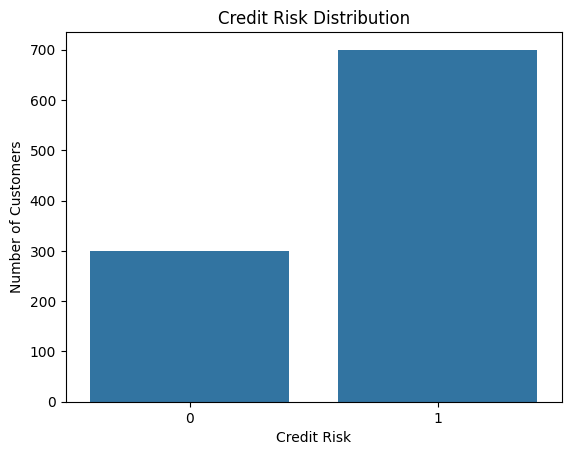

In [ ]:
## visualize all eda
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data=df,x="credit_risk")
plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
## The above tells us whether the target is balanced or imbalanced.

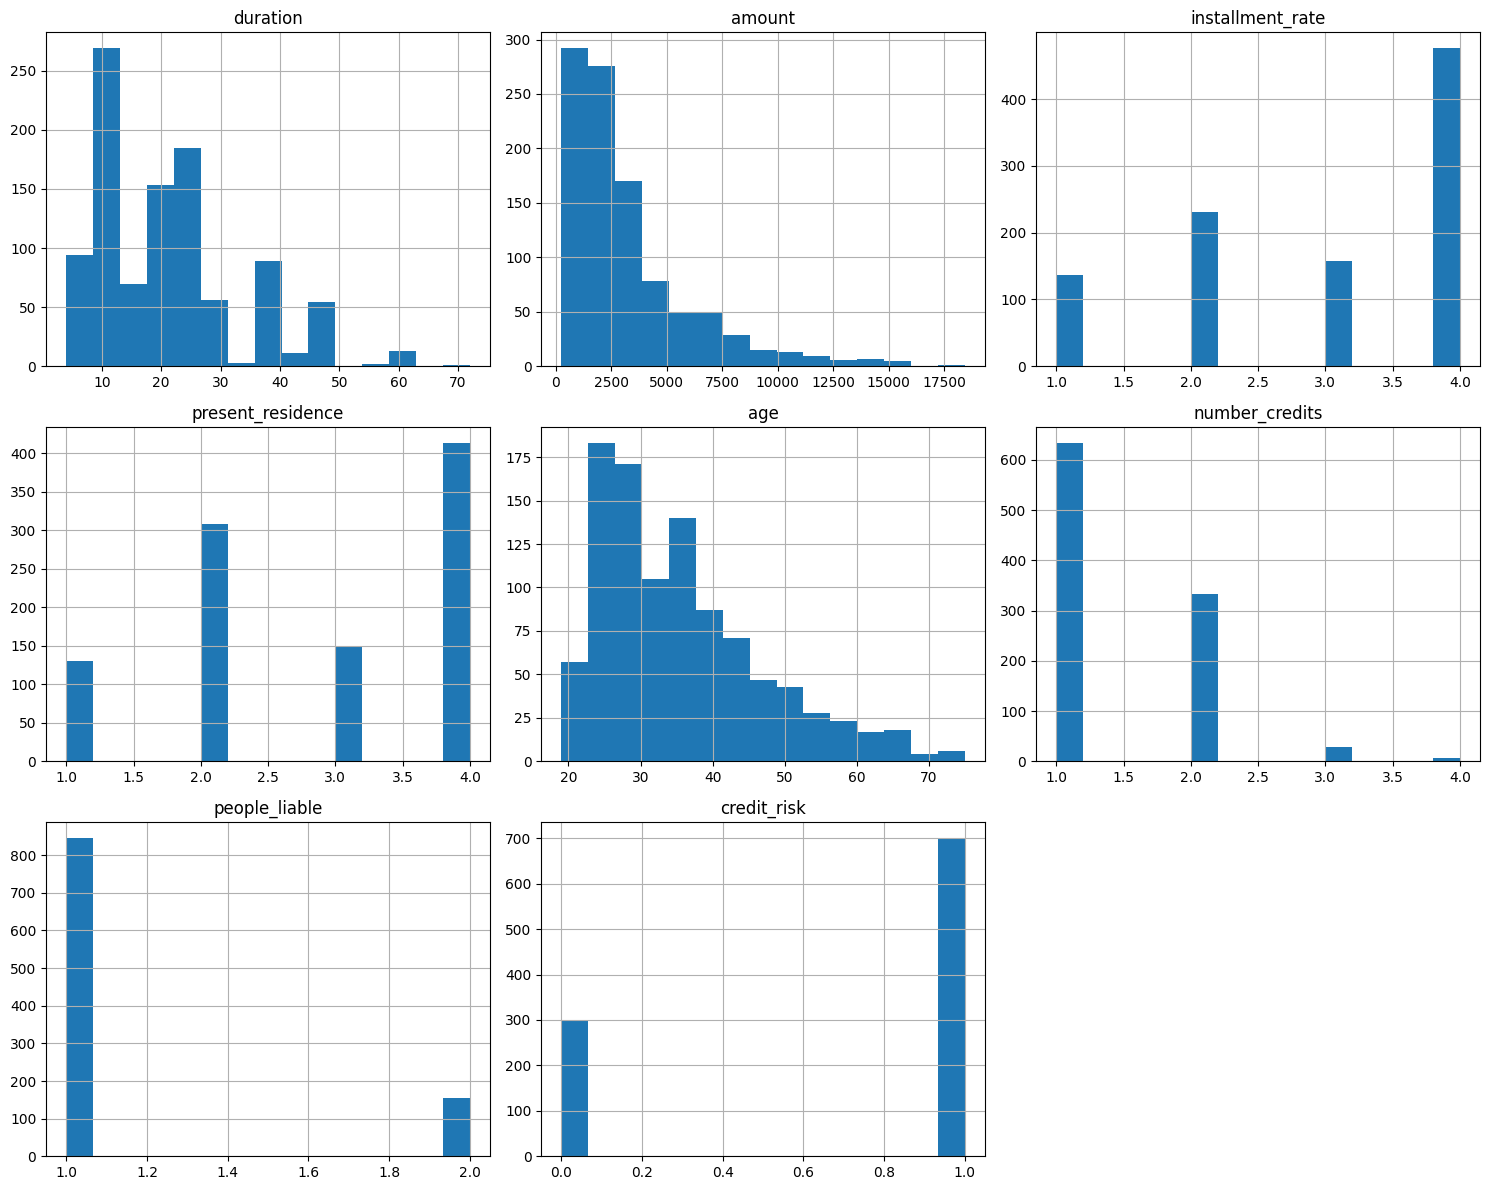

In [ ]:
## Numerical distributions
df[numeric_cols].hist(figsize=(15,12),bins=15)
plt.tight_layout()
plt.show()

In [ ]:
## This helps identify:
## skewness
## unusual values
## concentration
## possible outliers

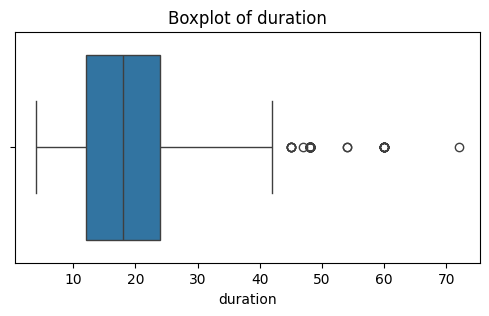

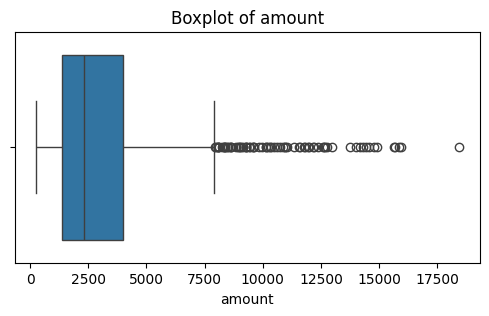

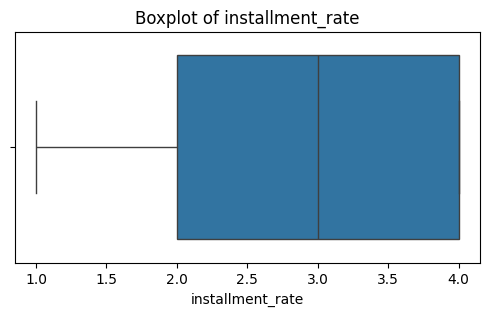

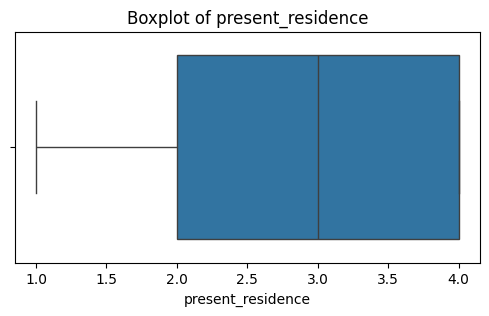

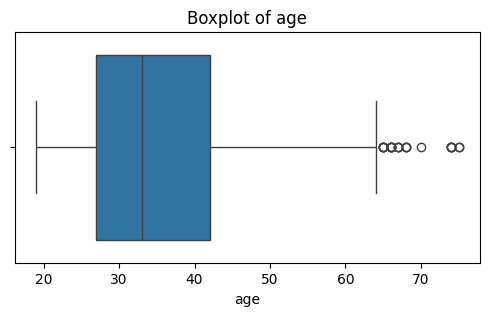

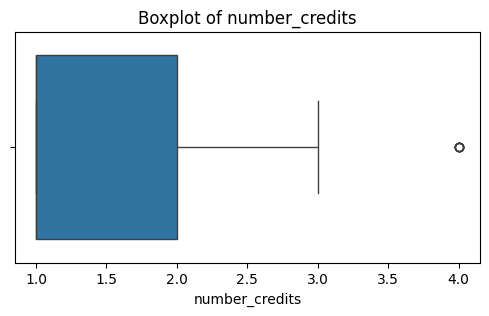

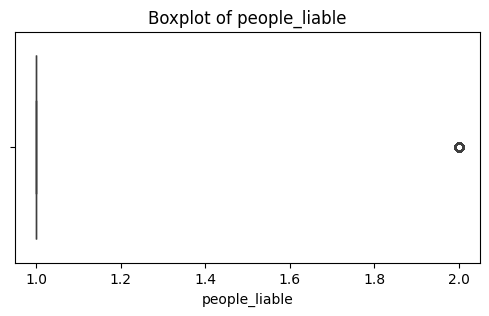

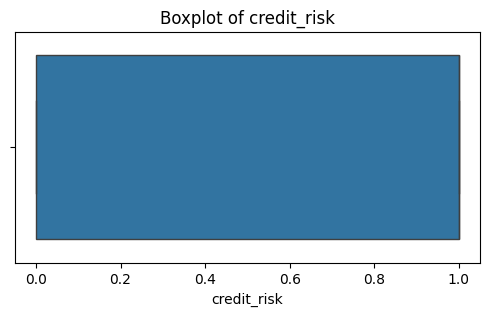

In [ ]:
## Boxplots for numerical columns
for col in numeric_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [ ]:
## boxplots help identifying potential outliers.

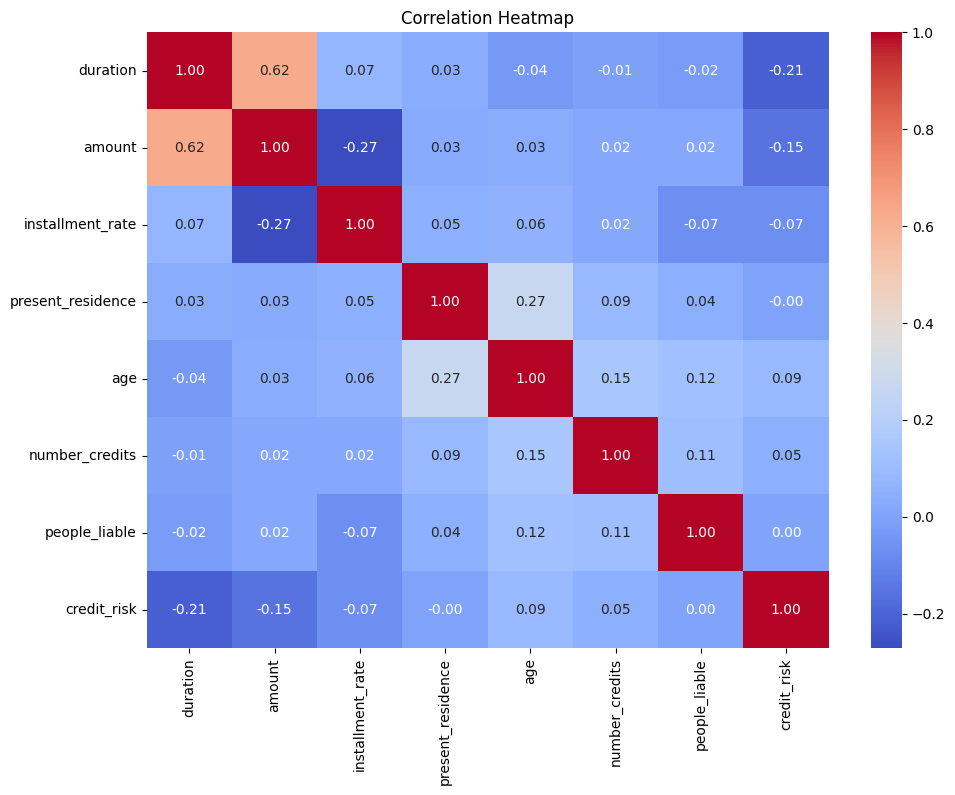

In [ ]:
## Correlation analysis
corr=df[numeric_cols].corr()
plt.figure(figsize=(11,8))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
## The above shows relationships between numerical variables.

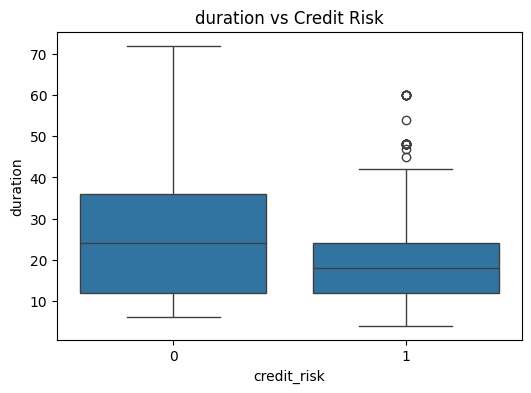

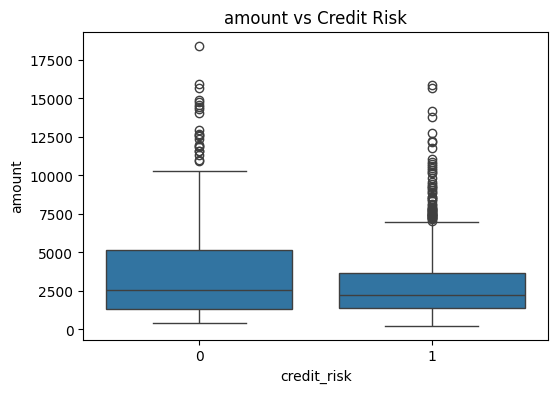

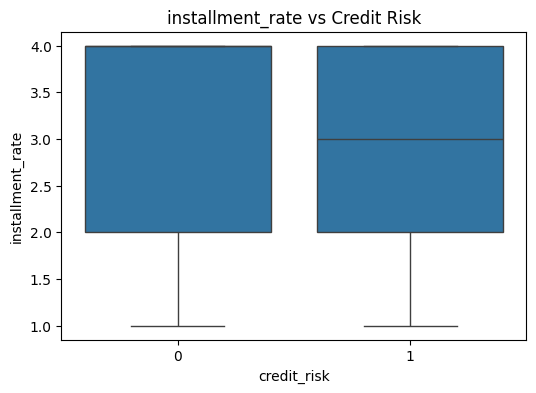

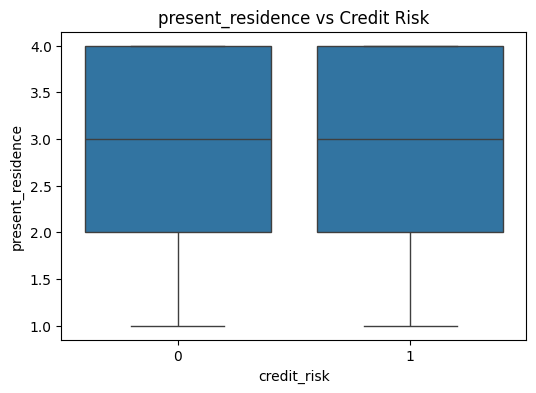

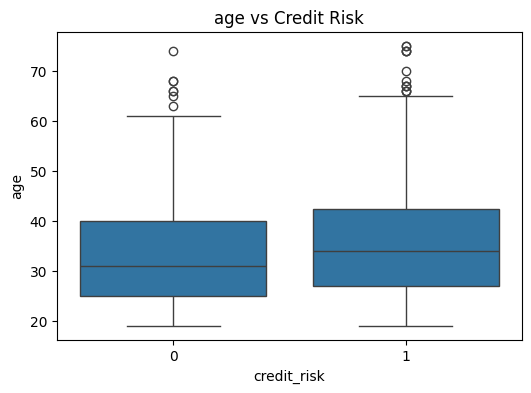

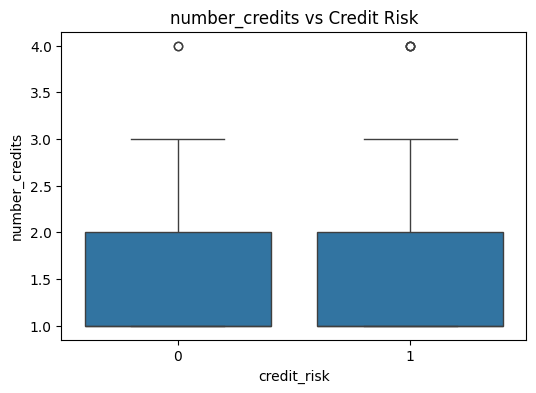

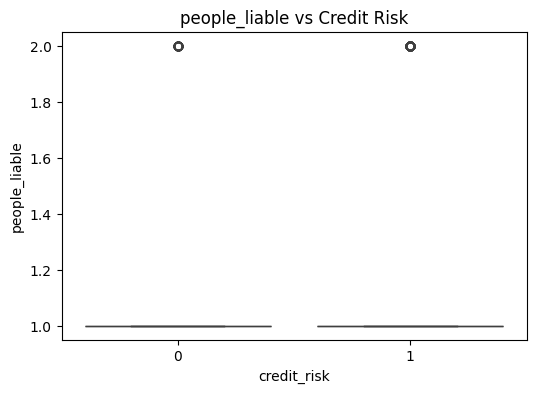

In [ ]:
## Numerical features vs credit risk
for col in numeric_cols:
    if col!="credit_risk":
        plt.figure(figsize=(6,4))
        sns.boxplot(data=df,x="credit_risk",y=col)
        plt.title(f"{col} vs Credit Risk")
        plt.show()

In [ ]:
## Credit risk by loan amount
df.groupby("credit_risk")["amount"].agg(["count","mean","median","min","max"])

,count,mean,median,min,max
credit_risk,,,,,
0,300,3938.126667,2574.5,433,18424
1,700,2985.457143,2244.0,250,15857


In [ ]:
## credit risk by age
df.groupby("credit_risk")["age"].agg(["count","mean","median","min","max"])

,count,mean,median,min,max
credit_risk,,,,,
0,300,33.963333,31.0,19,74
1,700,36.224286,34.0,19,75


In [ ]:
## Credit risk by purpose
pd.crosstab(df["purpose"],
    df["credit_risk"],
    normalize="index")*100

credit_risk,0,1
purpose,,
business,11.111111,88.888889
car (new),38.034188,61.965812
car (used),16.504854,83.495146
domestic appliances,22.142857,77.857143
education,36.363636,63.636364
furniture/equipment,41.666667,58.333333
others,35.051546,64.948454
radio/television,32.044199,67.955801
repairs,33.333333,66.666667


In [ ]:
## crosstab function to analyze the relationship between the 'purpose' of a loan and the 'credit_risk'.
## normalize='index', the values in each row are divided by the sum of that row. This effectively converts the counts into percentages within each 'purpose' category.

In [ ]:
## Create loan amount groups
df["amount_group"]=pd.cut(
    df["amount"],
    bins=[0,2000,5000,10000,20000,100000],
    labels=["0-2K","2K-5K","5K-10K","10K-20K","20K+"]
)

In [ ]:
pd.crosstab(
    df["amount_group"],
    df["credit_risk"],
    normalize="index"
)*100

credit_risk,0,1
amount_group,,
0-2K,28.009259,71.990741
2K-5K,26.578947,73.421053
5K-10K,36.486486,63.513514
10K-20K,60.000000,40.000000


In [ ]:
## check kurtosis
df[numeric_cols].kurt()

,0
duration,0.919781
amount,4.292590
installment_rate,-1.210473
present_residence,-1.381449
age,0.595780
number_credits,1.604439
people_liable,1.649274
credit_risk,-1.238284


In [ ]:
## check shswenwss
df[numeric_cols].skew()

,0
duration,1.094184
amount,1.949628
installment_rate,-0.531348
present_residence,-0.272570
age,1.020739
number_credits,1.272576
people_liable,1.909445
credit_risk,-0.874183


In [ ]:
## y-data profiling
!pip install ydata-profiling -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.3 MB/s eta 0:00:00


In [ ]:
from ydata_profiling import ProfileReport

profile=ProfileReport(df,title="Credit Risk EDA Report",explorative=True)
profile.to_notebook_iframe()

/tmp/ipykernel_1360/2594189355.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 22/22 [00:01<00:00, 15.23it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]